In [1]:
# import library
from time import time
from copy import deepcopy, copy
import csv
import matplotlib.pyplot as plt
from pathlib import Path

In [ ]:
# input parameters
time_unit = 1

cost_transportation = 1
cost_waiting = 0.5

step_size0 = 50    # stepsize & coefficient of penalty term
mu = 20    # parameter used to update step size
tau_incr = 1.5    # parameter used to update step size
tau_decr = 1.5    # parameter used to update step size
#num_neighbors = 10    # number of nearest requests

relative_tolerance = 0.001
threshold_time = 7200

# input files
dir_forder_raw = Path('..') / 'data'
dir_request = '10_request.csv'
dir_fleet = '10_fleet.csv'
dir_terminal = '10_terminal.csv'
dir_container_depot = '10_container depot.csv'
dir_travel_time = '10_traveltime_modified.csv'

# save
dir_forder_save = Path('..') / 'results'
save_name = 'nspucc-10'

In [3]:
# create object
class Request:
    def __init__(self):
        self.id = 0
        self.terminal_index = 0
        self.x = 0
        self.y = 0
        self.e = 0
        self.l = 0
        self.e_t = 0
        self.l_t = 0
        self.demand = 0
        self.type = 0
        self.service_time = 0
        self.service_time_t = 0
        
class Fleet:
    def __init__(self):
        self.id = 0
        self.x = 0
        self.y = 0
        self.e = 0
        self.l = 0
        self.capacity = 0
        
class Depot:
    def __init__(self):
        self.id = 0
        self.x = 0
        self.y = 0

In [4]:
# read data

# Read request data
len_cf = 0
len_sf = 0
list_request = []
with open(f'{dir_forder_raw}\\{dir_request}', 'r') as data:
    reader = csv.DictReader(data)
    for line in reader:
        r = Request()
        r.terminal_index = '0'*(3 - len(line['terminal index'])) + line['terminal index']
        r.id = '0'*(3 - len(line['index'])) + line['index']
        r.x = float(line['x'])
        r.y = float(line['y'])
        r.e = -(-int(line['e'])//time_unit) * time_unit    # time unit 단위로 올림
        r.l = int(line['l'])//time_unit*time_unit    # 내림
        r.e_t = -(-int(line['terminal e'])//time_unit) * time_unit    # 올림
        r.l_t = int(line['terminal l'])//time_unit*time_unit    # 내림
        r.demand = int(line['demand'])
        r.type = line['type'][0] + line['container'][0]
        r.service_time = max(2*time_unit, int(round(int(line['service time'])/(2*time_unit), 0) * 2 * time_unit))    # service time은 2*time unit의 배수여야함
        r.service_time_t = max(2*time_unit, int(round(int(line['terminal service time'])/(2*time_unit), 0) * 2 * time_unit))
        list_request.append(r)
        
        if r.type == 'cf':
            len_cf += 1
        elif r.type == 'sf':
            len_sf += 1
        if r.type in ['ce', 'se']:
            service_time_empty = r.service_time_t

# empty service time은 2*time unit의 배수여야함
service_time_empty = max(2*time_unit, int(round(service_time_empty/(2*time_unit), 0) * 2 * time_unit))

#num_neighbors = min(20, len(list_request)//2)
num_neighbors = 10

if num_neighbors <= len(list_request):
    num_farthest = len(list_request) - num_neighbors
else:
    num_farthest = 0

# read fleet data
list_fleet = []
with open(f'{dir_forder_raw}\\{dir_fleet}', 'r') as data:
    reader = csv.DictReader(data)
    
    # save minimum early time and maximum late time
    min_e = float('inf')
    max_l = 0
    for line in reader:
        f = Fleet()
        f.id = '0'*(3 - len(line['index'])) + line['index']
        f.x = float(line['x'])
        f.y = float(line['y'])
        f.e = -(-int(line['e'])//time_unit ) * time_unit    # 올림
        f.l = int(line['l'])//time_unit*time_unit    # 내림
        f.capacity = int(line['capacity'])
        list_fleet.append(f)
        
        if f.e < min_e:
            min_e = f.e
        if f.l > max_l:
            max_l = f.l

# function to read depot data
def read_depot(file_name):
    list_save = []
    with open(f'{dir_forder_raw}\\{file_name}', 'r') as data:
        reader = csv.DictReader(data)
        for line in reader:
            d = Depot()
            d.id = '0'*(3 - len(line['index'])) + line['index']
            d.x = float(line['x'])
            d.y = float(line['y'])
            list_save.append(d)
            
        return list_save
  
# read terminal data
list_terminal = read_depot(dir_terminal)
list_container_depot = read_depot(dir_container_depot)

In [5]:
# create arc dictionary - {(origin, time): {destin: [tt, cost, lr cost, admm cost, distance], destin: [], ...}
dict_arc = {}

# adding arc function
def add_arc(origin, destination, time, tt, cost, distance):
    node = (origin, time)
    if node not in dict_arc:
        dict_arc[node] = {}
    dict_arc[node][destination] = [tt, cost, cost, cost, distance]

# open travel time data
with open(f'{dir_forder_raw}\\{dir_travel_time}', 'r') as data:
    
    reader = csv.DictReader(data)
    for line in reader:
        
        distance = float(line['distance'])
        
        # travel time은 time unit으로 나눠 떨어져야함
        travel_time = int(round(float(line['travel time'])/time_unit, 0) * time_unit)
        
        # travel time은 time unit 이상이어야 함
        if travel_time == 0:
            travel_time = time_unit
            
        # travel time을 이용한 비용 계산
        cost = travel_time * cost_transportation
        if line['start'] == line['end']:    # waiting arc
            cost = travel_time * cost_waiting
        
        # depot는 출발, 도착 차고지 구분
        ts = f'ts{line["start"][-3:]}'
        te = f'te{line["end"][-3:]}'
        fleet = int(line['start'][-3:])
        
        # 출발 차고지로는 들어올 수 없고 도착 차고지에서는 나갈 수 없음 & 다른 차량의 차고지로 이동할 필요 없음
        if (line['start'][:2] == 'td') & (line['end'][:2] == 'td') & (line['start'][-3:] == line['end'][-3:]):
            add_arc(ts, ts, int(line['time']), travel_time, 0, 0)
            add_arc(ts, te, int(line['time']), travel_time, 0, 0)
            # te에서 waiting은 필요 없음. 바로 끝
            add_arc(te, te, int(line['time']), list_fleet[fleet].l - int(line['time']), 0, 0)
        elif (line['start'][:2] == 'td') & (line['end'][:2] != 'td'):
            add_arc(ts, line['end'], int(line['time']), travel_time, cost, distance)
        elif (line['start'][:2] != 'td') & (line['end'][:2] == 'td'):
            add_arc(line['start'], te, int(line['time']), travel_time, cost, distance)
        elif (line['start'][:2] != 'td') & (line['end'][:2] != 'td'):
            add_arc(line['start'], line['end'], int(line['time']), travel_time, cost, distance)
    
# add dummy nodes
for request in list_request:
    
    if request.type[1] == 'f':
        for t in range(request.e_t - request.service_time_t//2, request.l_t - request.service_time_t//2 + time_unit, time_unit):
            add_arc(f'tm{request.terminal_index}', f'tmd{request.id}', t, request.service_time_t//2, (request.service_time_t//2) * cost_waiting, 0)
            add_arc(f'tmd{request.id}', f'tm{request.terminal_index}', t + request.service_time_t//2, request.service_time_t//2, (request.service_time_t//2) * cost_waiting, 0)
    for t in range(request.e - request.service_time//2, request.l - request.service_time//2 + time_unit, time_unit):
        add_arc(f'{request.type}{request.id}', f'{request.type}d{request.id}', t, request.service_time//2, (request.service_time//2) * cost_waiting, 0)
        add_arc(f'{request.type}d{request.id}', f'{request.type}{request.id}', t + request.service_time//2, request.service_time//2, (request.service_time//2) * cost_waiting, 0)

# container depot의 더미 노드
for cd in list_container_depot:
    for t in range(min_e, max_l + time_unit, time_unit):
        for i in [1, 2]:
            add_arc(f'cd{cd.id}', f'cdp{i}{cd.id}', t, service_time_empty//2, service_time_empty//2 * cost_waiting, 0)
            add_arc(f'cdp{i}{cd.id}', f'cd{cd.id}', t, service_time_empty//2, service_time_empty//2 * cost_waiting, 0)
            add_arc(f'cd{cd.id}', f'cdd{i}{cd.id}', t, service_time_empty//2, service_time_empty//2 * cost_waiting, 0)
            add_arc(f'cdd{i}{cd.id}', f'cd{cd.id}', t, service_time_empty//2, service_time_empty//2 * cost_waiting, 0)

In [6]:
# 각 empty 요청지에서 가장 가까운 컨테이너 창고를 terminal index에 저장
for request in list_request:
    if request.type[1] == 'e':
        cheapest_cost = float('inf')
        for cd in list_container_depot:
            cost = dict_arc[f'{request.type}{request.id}', request.e][f'cd{cd.id}'][1]
            if cost < cheapest_cost:
                cheapest_cost = cost
                cheapest_cd = cd.id
        request.terminal_index = cheapest_cd

# 각 차량이 각 request를 수행하는데 드는 비용. 통행시간은 해당 차량의 early time 기준
def cal_cost(fleet, service_time1, service_time2, pickup, dropoff):
    time1 = dict_arc[(f'ts{fleet.id}', fleet.e)][pickup][1]
    time2 = dict_arc[(pickup, time1)][dropoff][1]
    time3 = dict_arc[(dropoff, time2)][f'te{fleet.id}'][1]
    return time1 + time2 + time3 + service_time1 * cost_waiting + service_time2 * cost_waiting

cost_request = {fleet.id: {} for fleet in list_fleet}
for fleet in list_fleet:
    for request in list_request:
        # tw가 차량 운영시간 안에 있어야 가능
        if (request.e >= fleet.e) & (request.e <= fleet.l) & (((request.e_t >= fleet.e) & (request.e_t <= fleet.l)) | (request.e_t == -1)):
            if request.type == 'cf':
                cost_request[fleet.id][request.type + request.id] = cal_cost(fleet, request.service_time_t, request.service_time, f'tm{request.terminal_index}', f'{request.type}{request.id}')
            elif request.type == 'sf':
                cost_request[fleet.id][request.type + request.id] = cal_cost(fleet, request.service_time, request.service_time_t, f'{request.type}{request.id}', f'tm{request.terminal_index}')
            elif request.type == 'ce':
                cost_request[fleet.id][request.type + request.id] = cal_cost(fleet, request.service_time, service_time_empty, f'{request.type}{request.id}', f'cd{request.terminal_index}')
            elif request.type == 'se':
                cost_request[fleet.id][request.type + request.id] = cal_cost(fleet, service_time_empty, request.service_time, f'cd{request.terminal_index}', f'{request.type}{request.id}')
        else:
            cost_request[fleet.id][request.type + request.id] = float('inf')

In [7]:
# calculate the number of arcs
def dict_arc_length(dict_arc):
    length = 0
    for i in dict_arc:
        length += len(dict_arc[i])
    return length

print('The number of arcs before processed:', dict_arc_length(dict_arc))

# delete unnecessary arcs
for node_origin in dict_arc:
    for destin, attribute in deepcopy(dict_arc[node_origin]).items():
        
        request_origin = list_request[int(node_origin[0][-3:])]
        request_destin = list_request[int(destin[-3:])]
        
        # dummy node들은 이미 가능한 애들만 들어있음
        if (node_origin[0][2] in {'p', 'd'}) | (destin[2] in {'p', 'd'}):
            continue
        
        # 대기하는 arc도 다 최적 후보
        if (node_origin[0] == destin):
            continue
        
        # 각 요청의 early time보다 이른 시각에 해당 요청지에서 다른 곳으로 가는 건 최적이 아님
        if (node_origin[0][:2] in {'cf', 'sf', 'ce', 'se'}) & (node_origin[1] < request_origin.e + request_origin.service_time//2):
            del dict_arc[node_origin][destin]
        
        # 각 요청의 late time보다 늦은 시각에 해당 요청지로 가는 것은 최적이 아님
        elif (destin[:2] in {'cf', 'sf', 'ce', 'se'}) & (node_origin[1] + attribute[0] > request_destin.l - request_destin.service_time//2):
            del dict_arc[node_origin][destin]
        
print('The number of arcs before processed:', dict_arc_length(dict_arc))

The number of arcs before processed: 1784246
The number of arcs before processed: 558162


In [8]:

# 모든 위치 확인. 더미 제외
all_locations = []
for request in list_request:
    all_locations.append(f'{request.type}{request.id}')
for terminal in list_terminal:
    all_locations.append(f'tm{terminal.id}')
for cd in list_container_depot:
    all_locations.append(f'cd{cd.id}')
    for i in [1, 2]:
        all_locations.append(f'cdp{i}{cd.id}')
        all_locations.append(f'cdd{i}{cd.id}')
    
# 더미 노드의 시간 : 위치 딕셔너리 생성, done 배열 생성
dict_dummy_time = {t: [] for t in range(min_e, max_l + time_unit, time_unit)}
dict_dones = {t: [frozenset()] for t in range(min_e, max_l + time_unit, time_unit)}
for request in list_request:
    for t in range(request.e, request.l + time_unit, time_unit):
        dict_dummy_time[t].append(f'{request.type}d{request.id}')
        for done in copy(dict_dones[t]):
            dict_dones[t].append(frozenset(list(done) + [f'{request.type}d{request.id}']))
    if request.type[1] == 'f':
        for t in range(request.e_t, request.l_t + time_unit, time_unit):
            dict_dummy_time[t].append(f'tmd{request.id}')
            for done in copy(dict_dones[t]):
                dict_dones[t].append(frozenset(list(done) + [f'tmd{request.id}']))
                
initial_state = tuple(0 for _ in range(len_cf + len_sf + 2))

In [9]:
def cdp1(state, node_id):
    state[-2] += 1
    if sum(state) > fleet.capacity:
        return None
    return state

def cdp2(state, node_id):
    state[-1] += 2
    if sum(state) > fleet.capacity:
        return None
    return state

def cdd1(state, node_id):
    state[-2] -= 1
    if state[-2] < 0:
        return None
    return state

def cdd2(state, node_id):
    state[-1] -= 2
    if state[-1] < 0:
        return None
    return state

def ced(state, node_id):
    if list_request[node_id].demand % 2 == 1:
        state[-2] += list_request[node_id].demand
    else:
        state[-1] += list_request[node_id].demand
    if (sum(state) > fleet.capacity) | (state[-1] < 0) | (state[-2] < 0):
        return None
    return state

def sed(state, node_id):
    if list_request[node_id].demand % 2 == 1:
        state[-2] += list_request[node_id].demand
    else:
        state[-1] += list_request[node_id].demand
    if (sum(state) > fleet.capacity) | (state[-1] < 0) | (state[-2] < 0):
        return None
    return state

def tmd(state, node_id):
    state[node_id] -= list_request[node_id].demand
    if (sum(state) > fleet.capacity) | (state[node_id] < 0):
        return None
    return state

def sfd(state, node_id):
    state[node_id] += list_request[node_id].demand
    if (sum(state) > fleet.capacity) | (state[node_id] < 0):
        return None
    return state

def cfd(state, node_id):
    state[node_id] += list_request[node_id].demand
    if (sum(state) > fleet.capacity) | (state[node_id] < 0):
        return None
    return state

def others(state, node_id):
    return state

state_change = {'cdp1': cdp1, 'cdp2': cdp2, 'cdd1': cdd1, 'cdd2': cdd2, 'ced': ced, 'sed': sed, 'tmd': tmd, 'sfd': sfd, 'cfd': cfd, 'tm': others, 'cf': others, 'sf': others, 'ce': others, 'se': others, 'cd': others, 'te': others, 'ts': others}

In [10]:
# Dynamic programming - least cost path
def dynamic_programming(fleet, conducted, dict_arc_, farthest_request):

    conducted = deepcopy(conducted)
    
    if farthest_request:
        for request in farthest_request:
            if request[2] == 'f':
                farthest_request.add(f'tmd{request[-3:]}')
                
        dict_arc = {}
        for origin in dict_arc_:
            dict_arc[origin] = {}
            for destin in dict_arc_[origin]:
                if destin not in farthest_request:
                    dict_arc[origin][destin] = copy(dict_arc_[origin][destin])
    
    else:
        dict_arc = dict_arc_
    
    # create result table - 시간 딕셔너리 안에 위치 딕셔너리 안에 state: memory 딕셔너리가 있는 구조
    result = {(time, location, done): {} for time in range(fleet.e, fleet.l + time_unit, time_unit) for location in all_locations + [f'ts{fleet.id}', f'te{fleet.id}'] + dict_dummy_time[time] for done in dict_dones[time]}
    
    # 탐색한 노드 개수
    num_explored = 0
    
    # state는 full 요청 수 + 1 개의 요소를 가짐. 마지막 요소는 빈 컨테이너의 개수
    # memory는 3개의 cost와 이전 노드, 거리 정보를 가짐
    result[(fleet.e, f'ts{fleet.id}', frozenset())] = {initial_state: (0, 0, 0, 0, (0, 0, 0, 0))}
    
    for time_now in range(fleet.e, fleet.l, time_unit):
        for location_now in all_locations + [f'ts{fleet.id}', f'te{fleet.id}'] + dict_dummy_time[time_now]:
            for done_now in dict_dones[time_now]:
                
                for state_now in result[(time_now, location_now, done_now)]:
                    
                    # tw가 지나 수행이 불가능한 화물을 싣고 있는 경우 제거
                    skip = False
                    for request_id in range(len_cf + len_sf):
                        if state_now[request_id] > 0:
                            if (list_request[request_id].type == 'cf') & (time_now > list_request[request_id].l):
                                skip = True
                                break
                            elif (list_request[request_id].type == 'sf') & (time_now > list_request[request_id].l_t):
                                skip = True
                                break
                    if skip:
                        continue
                        
                    for destin, attribute in dict_arc[(location_now, time_now)].items():
                        
                        # 다른 fleet의 depot로 가는 arc인 경우 제외
                        if (destin[:2]=='te') & (destin[-3:] != fleet.id):
                            continue
                        
                        # time update
                        time_next = time_now + attribute[0]
                        
                        # 도착 시간이 fleet의 late time을 넘어가면 도착 불가
                        if time_next > fleet.l:
                            continue
                        
                        done = set(done_now)
                        
                        num_explored += 1
                        
                        node_id = int(destin[-3:])
                        state = list(state_now)
                        
                        # 이미 수행한 요청 다시 수행 불가
                        if destin in done:
                            continue
                        elif destin[:3] in {'tmd', 'cfd', 'sfd', 'ced', 'sed'}:
                            done.add(destin)
                        
                        # 목적지가 dummy면 state 변경
                        state = state_change[destin[:-3]](state, node_id)
                        if state is None:
                            continue
                            
                        # 다음 시간에 done의 요청 중 tw가 끝나는 요청은 done에서 제외
                        if done:
                            for request in copy(done):
                                if request[:3] == 'tmd':
                                    if time_next >= list_request[int(request[-3:])].l_t:
                                        done.remove(request)
                                else:
                                    if time_next >= list_request[int(request[-3:])].l:
                                        done.remove(request)
                        
                        state = tuple(state)
                        done = frozenset(done)
                        
                        attribute_result = result[(time_now, location_now, done_now)][state_now]
                        
                        # attribute update
                        cost_next = attribute_result[0] + attribute[1]
                        cost_lr_next = attribute_result[1] + attribute[2]
                        cost_admm_next = attribute_result[2] + attribute[3]
                        distance_next = attribute_result[3] + attribute[4]
                        
                        # update result
                        if state in result[(time_next, destin, done)]:
                            if cost_admm_next < result[(time_next, destin, done)][state][2]:
                                result[(time_next, destin, done)][state] = (cost_next, cost_lr_next, cost_admm_next, distance_next, (time_now, location_now, done_now, state_now))
                        else:
                            result[(time_next, destin, done)][state] = (cost_next, cost_lr_next, cost_admm_next, distance_next, (time_now, location_now, done_now, state_now))
    
    # 최종 노드의 done을 빈 집합으로 변경
    cost_final = 9999999
    for done in dict_dones[fleet.l]:
        if initial_state in result[(fleet.l, f'te{fleet.id}', done)]:
            cost = result[(fleet.l, f'te{fleet.id}', done)][initial_state][2]
            if cost_final > cost:
                cost_final = cost
                node_final = (fleet.l, f'te{fleet.id}', done, initial_state)
    
    # 결과 출력
    # 수행 여부 0으로 초기화
    for key in conducted[fleet.id]:
        conducted[fleet.id][key] = 0
    node_present = node_final
    
    # 경로 되짚어보기
    path = []
    path.append(node_present)
    while node_present[0] > fleet.e:
        node_present = result[node_present[:3]][node_present[3]][4]
        path.append(node_present)
        if node_present[1] in conducted[fleet.id].keys():
            conducted[fleet.id][node_present[1]] += 1
            
    return *result[node_final[:3]][node_final[3]][:4], path[::-1], conducted, num_explored

In [11]:
# cost update
def cal_cost(dict_arc, dict_lm, step_size, conducted, fleet, cost_request, num_farthest):
            
    cost_request = copy(cost_request[fleet.id])
    
    for request in list_request:
        type = request.type
        id = request.id
        
        # admm penalty
        penalty = step_size*sum(pick[f'{type}d{id}'] for key, pick in conducted.items() if key != fleet.id) - 0.5*step_size
        
        # cost_request update
        cost_request[f'{type}{id}'] += dict_lm[f'{type}d{id}'] + penalty
        
        for t in range(request.e - request.service_time//2, request.l - request.service_time//2 + time_unit, time_unit):
            
            dict_arc[(f'{type}{id}', t)][f'{type}d{id}'][2] = dict_arc[(f'{type}{id}', t)][f'{type}d{id}'][1] + dict_lm[f'{type}d{id}']
            dict_arc[(f'{type}{id}', t)][f'{type}d{id}'][3] = dict_arc[(f'{type}{id}', t)][f'{type}d{id}'][1] + dict_lm[f'{type}d{id}'] + penalty
            
    # 먼 요청 반환.
    farthest_request = set((key for key, value in sorted(cost_request.items(), key=lambda x: x[1], reverse=True)[:num_farthest]))
    
    return dict_arc, farthest_request

In [12]:
# ADMM

# initialize the variables
dict_lm = {f'{request.type}d{request.id}': 0 for request in list_request}
step_size = step_size0
conducted = {fleet.id: {key: 0 for key in dict_lm} for fleet in list_fleet}
conducted_sum = {key: 0 for key in dict_lm}
final_conducted = {fleet.id: {key: 0 for key in dict_lm} for fleet in list_fleet}
residual_primal = float('inf')

lb = -float('inf')
residual_primal_final = float('inf')

time_start = time()
k = 0

result_cost = {fleet.id: 0 for fleet in list_fleet}
result_distance = {fleet.id: 0 for fleet in list_fleet}
result_path = {fleet.id: [] for fleet in list_fleet}
result_lm = {key: [dict_lm[key]] for key in dict_lm}
result_num_violated = {}

# iteration
while True:
    
    k += 1
    
    if k == 4:
        if len(list_request)/2 > 10:
            num_farthest = round(len(list_request)/2)
    elif k == 7:
        num_farthest = 0
        step_size = 14.81
    
    # save the previous result
    conducted_sum_previous = copy(conducted_sum)
    residual_primal_previous = residual_primal
    dict_lm_previous = copy(dict_lm)
    
    # 초반 10번과 그 이후 3번째마다 전체 차량의 경로 최적화
    if (k % 3 == 1) | (k <= 6):
        
        print('______________________________________________________')
        
        conducted_previous = deepcopy(conducted)
        
        # dynamic programming
        for fleet in list_fleet:
            
            # arc cost update
            dict_arc, farthest_request = cal_cost(dict_arc, dict_lm, step_size, conducted, fleet, cost_request, num_farthest)
            
            # dynamic programming
            _, result_cost[fleet.id], _, result_distance[fleet.id], result_path[fleet.id], conducted, num_explored = dynamic_programming(fleet, conducted, dict_arc, farthest_request)
            
            # print the progress
            print(f'Vehicle {int(fleet.id)+1} processed, {num_explored} nodes explored')
            
            result_num_violated[k] = len(list_fleet)
        
    # 부분 업데이트 - 경로가 바뀐 + primal 조건을 어기는 요청을 수행하는 차량의 경로만 최적화
    else:
        
        # primal 조건을 어기는 요청 찾기
        dict_violated = {}
        for request, num_conducted in conducted_sum.items():
            if num_conducted > 1:
                dict_violated[request] = num_conducted
                
        # 부분 업데이트 대상 차량 찾기
        dict_changed = {fleet.id: 0 for fleet in list_fleet}
        for fleet in list_fleet:
            # 경로가 바뀐 차량
            if conducted_previous[fleet.id] != conducted[fleet.id]:
                dict_changed[fleet.id] += step_size_previous * abs(sum(conducted_previous[fleet.id][i] - conducted[fleet.id][i] for i in conducted[fleet.id]))
            for request in dict_violated:
                if conducted[fleet.id][request] > 0:
                    dict_changed[fleet.id] += 1
        print(dict_changed)
        
        # 가장 크게 위반한 차량 순으로 정렬
        dict_changed = {key: value for key, value in sorted(dict_changed.items(), key=lambda x: x[1], reverse=True)}
        
        list_to_be_updated = [list_fleet[int(fleet_id)] for fleet_id in dict_changed if dict_changed[fleet_id] > 0]
        result_num_violated[k] = len(list_to_be_updated)
        if len(list_to_be_updated) > len(list_fleet)//2:
            list_to_be_updated = list_to_be_updated[:len(list_fleet)//2]
                
        conducted_previous = deepcopy(conducted)
        
        for fleet in list_to_be_updated:
            
            # arc cost update
            dict_arc, farthest_request = cal_cost(dict_arc, dict_lm, step_size, conducted, fleet, cost_request, num_farthest)
            
            # dynamic programming
            _, result_cost[fleet.id], _, result_distance[fleet.id], result_path[fleet.id], conducted, num_explored = dynamic_programming(fleet, conducted, dict_arc, farthest_request)
            
            # print the progress
            print(f'Vehicle {int(fleet.id)+1} processed, {num_explored} nodes explored')
    
    # step size 저장
    step_size_previous = step_size
    
    # update the multipliers
    conducted_sum = {key: 0 for key in dict_lm}
    for key in dict_lm:
        for fleet in list_fleet:
            conducted_sum[key] += conducted[fleet.id][key]
        dict_lm[key] += step_size*(conducted_sum[key] - 1)
        result_lm[key].append(dict_lm[key])
    
    # calculate residuals
    residual_primal = sum((i - 1)**2 for i in conducted_sum.values())**0.5
    residual_dual = step_size * sum((conducted_sum[i] - conducted_sum_previous[i])**2 for i in conducted_sum)**0.5
            
    # update the step size
    if (k % 3 == 1) | (k <= 6):
        
        # update the lower bound
        lb_temp = sum(result_cost.values()) - sum(dict_lm_previous.values())
        if (residual_primal <= residual_primal_final):
            lb = lb_temp
            residual_primal_final = residual_primal
            distance = sum(result_distance.values())
            paths = {fleet_id: copy(path) for fleet_id, path in result_path.items()}
            final_lm = copy(dict_lm_previous)
            for fleet in list_fleet:
                final_conducted[fleet.id] = copy(conducted_previous[fleet.id])
        
        # termination test(전체 차량에 대해 최적화했을 경우에만 수행)
        if residual_primal <= relative_tolerance:
            if step_size > 100:
                print(f'****************************************************** \
                    \nThe present value is {round(sum(result_cost.values()) - sum(dict_lm_previous.values()), 2)} \
                    \n******************************************************')
                k -= 1
                
            else:
                break
            
        # update the step size
        if residual_primal > mu * residual_dual:
            step_size = round(step_size * tau_incr, 2)
        elif (residual_dual > mu * residual_primal) | (residual_primal == 0):
            step_size = round(step_size / tau_decr, 2)
            
    if time() - time_start > threshold_time:
        break
        
    # print the result
    print(f'Iteration number {k}, ({round(time()-time_start, 1)} seconds passed) \
        \nLower bound for this iteration : {round(sum(result_cost.values()) - sum(dict_lm_previous.values()), 2)} \
        \nBest lower bound : {round(lb, 2)} \
        \nPrimal residual : {residual_primal} \
        \nDual residual : {residual_dual} \
        \nStep size : {step_size_previous} \
        \nLagrangian multiplier : {dict_lm_previous} \
        \n______________________________________________________')

print(f'The iteration is terminated after {k}, ({round(time()-time_start, 1)} seconds passed) \
    \nThe lower bound is {round(lb, 2)} \
    \nPrimal residual : {residual_primal} \
    \nDual residual : {residual_dual} \
    \nStep size : {step_size_previous} \
    \nTotal travel distance is {round(distance, 2)}')
for fleet in list_fleet:
    print(f'The route of fleet {int(fleet.id) + 1} is {paths[fleet.id]}')
for request, lm in result_lm.items():
    print(f'The Lagrangian multiplier of {request} is {lm}')

______________________________________________________
Vehicle 1 processed, 810591 nodes explored
Vehicle 2 processed, 766947 nodes explored
Vehicle 3 processed, 239229 nodes explored
Vehicle 4 processed, 239229 nodes explored
Vehicle 5 processed, 239229 nodes explored
Vehicle 6 processed, 766947 nodes explored
Vehicle 7 processed, 766947 nodes explored
Vehicle 8 processed, 256263 nodes explored
Vehicle 9 processed, 245668 nodes explored
Vehicle 10 processed, 800769 nodes explored
Vehicle 11 processed, 800769 nodes explored
Vehicle 12 processed, 245350 nodes explored
Vehicle 13 processed, 245350 nodes explored
Vehicle 14 processed, 244859 nodes explored
Vehicle 15 processed, 767777 nodes explored
Vehicle 16 processed, 920722 nodes explored
Vehicle 17 processed, 276057 nodes explored
Vehicle 18 processed, 276057 nodes explored
Iteration number 1, (28.7 seconds passed)         
Lower bound for this iteration : 220.5         
Best lower bound : 220.5         
Primal residual : 6.244997998

In [13]:
dict_arc_copy = deepcopy(dict_arc)
conducted_ub = deepcopy(final_conducted)

for fleet in list_fleet:
    
    # cost update
    dict_arc_copy, farthest_request = cal_cost(dict_arc_copy, final_lm, step_size_previous, conducted_ub, fleet, cost_request, num_farthest)
    
    # dynamic programming
    result_cost[fleet.id], _, _, result_distance[fleet.id], result_path[fleet.id], conducted_ub, num_explored = dynamic_programming(fleet, conducted_ub, dict_arc_copy, farthest_request)
    
    # set the cost of conducted requests to inf
    for request, value in conducted_ub[fleet.id].items():
        if value == 1:
            for t in range(list_request[int(request[-3:])].e - list_request[int(request[-3:])].service_time//2, list_request[int(request[-3:])].l - list_request[int(request[-3:])].service_time//2 + time_unit, time_unit):
                dict_arc_copy[(f'{request[:2]}{request[-3:]}', t)][request][1] = 99999
                dict_arc_copy[(f'{request[:2]}{request[-3:]}', t)][request][3] = 99999

# 수행되지 않은 요청 체크
conducted_sum = {request: 0 for request in dict_lm}
unconducted = []
for key in dict_lm:
    for fleet in list_fleet:
        conducted_sum[key] += conducted_ub[fleet.id][key]
    if conducted_sum[key] == 0:
        unconducted.append(key)
        
for key in unconducted:        
    request = list_request[int(key[-3:])]
    
    # 미수행 요청의 admm cost를 -inf로 변경
    e = request.e
    l = request.l
    real = f'{key[:2]}{key[-3:]}'    # real request
    
    for t in range(e - request.service_time//2, l - request.service_time//2 + time_unit, time_unit):
        dict_arc_copy[(real, t)][key][3] = -99999

# 운행하지 않은 차량 확인
unconducted_fleet = []
for fleet in list_fleet:
    if len(result_path[fleet.id]) <= 3:
        unconducted_fleet.append(fleet)
        
# 운행하지 않은 차량의 경로탐색 수행
for fleet in unconducted_fleet:
    
    # dynamic programming
    result_cost[fleet.id], _, _, result_distance[fleet.id], result_path[fleet.id], conducted_ub, num_explored = dynamic_programming(fleet, conducted_ub, dict_arc_copy, farthest_request)
    
    # set the cost of conducted requests to inf
    for request, value in conducted_ub[fleet.id].items():
        if value == 1:
            for t in range(list_request[int(request[-3:])].e - list_request[int(request[-3:])].service_time//2, list_request[int(request[-3:])].l - list_request[int(request[-3:])].service_time//2 + time_unit, time_unit):
                dict_arc_copy[(f'{request[:2]}{request[-3:]}', t)][request][3] = 99999

# 수행되지 않은 요청 체크
conducted_sum = {request: 0 for request in dict_lm}
for key in dict_lm:
    for fleet in list_fleet:
        conducted_sum[key] += conducted_ub[fleet.id][key]
    if conducted_sum[key] == 0:
        print('ERROR')

total_cost = sum(result_cost.values())
total_distance = sum(result_distance.values())
            
print(f'The upper bound is {round(total_cost, 2)} \
    \nTotal travel distance is {round(total_distance, 2)}')
for fleet in list_fleet:
    print(f'The route of fleet {int(fleet.id) + 1} is {result_path[fleet.id]}')

The upper bound is 1786.0     
Total travel distance is 1343.35
The route of fleet 1 is [(0, 'ts000', frozenset(), (0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0)), (1, 'ts000', frozenset(), (0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0)), (2, 'ts000', frozenset(), (0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0)), (3, 'ts000', frozenset(), (0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0)), (4, 'ts000', frozenset(), (0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0)), (5, 'ts000', frozenset(), (0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0)), (6, 'ts000', frozenset(), (0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0)), (7, 'ts000', frozenset(), (0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0)), (8, 'ts000', frozenset(), (0, 0, 0, 0, 0, 0, 0, 0, 0, 0

In [14]:
# travel time 계산
travel_time = 0
for fleet in list_fleet:
    for node in result_path[fleet.id]:
        if node[1][:2] == 'ts':
            pin = node[0]
        elif node[1][:2] == 'te':
            travel_time += node[0] - pin
            break
    
print(f'Total travel time is {travel_time}')

Total travel time is 2222


In [15]:
# 평균 적재 컨테이너수 구하기
sum_container = 0
sum_time = 0
for fleet in list_fleet:
    if len(result_path[fleet.id]) > 3:
        sum_time += result_path[fleet.id][-1][0] - result_path[fleet.id][0][0]
        for i in range(len(result_path[fleet.id]) - 1):
            sum_container += sum(result_path[fleet.id][i][3]) * (result_path[fleet.id][i+1][0] - result_path[fleet.id][i][0])
avg_container = sum_container / sum_time
print(f'The average number of containers in the fleet is {round(avg_container, 2)}')

# 시간대별 적재 컨테이너수 구하기
time_container = {t: 0 for t in range(min_e, max_l + time_unit, time_unit)}
sum_container_mid = 0
sum_time_mid = 0
use_fleet = 0
for fleet in list_fleet:
    if len(result_path[fleet.id]) > 3:
        use_fleet += 1
        sum_time_mid += result_path[fleet.id][-1][0] - result_path[fleet.id][0][0] - 100
        for i in range(len(result_path[fleet.id]) - 1):
            for t in range(result_path[fleet.id][i][0], result_path[fleet.id][i+1][0], time_unit):
                time_container[t] += sum(result_path[fleet.id][i][3])
                if (t >= 50 + fleet.e) & (t <= fleet.l - 50):
                    sum_container_mid += sum(result_path[fleet.id][i][3])
sum_container_mid /= sum_time_mid
print(f'The average number of containers in the fleet at the peak period is {round(sum_container_mid, 2)}')

for t in time_container:
    time_container[t] /= use_fleet

# visualization
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(time_container.keys(), time_container.values(), label='Number of containers', color='black')
ax.set_xlabel('Time')
ax.set_ylabel('Number of loaded containers')
ax.set_title('Number of loaded containers by time')

plt.close(fig)

The average number of containers in the fleet is 1.03
The average number of containers in the fleet at the peak period is 1.41


In [ ]:
from time import time

# 파일 생성
result_text = (
    f'The iteration is terminated after {k}, ({round(time()-time_start, 1)} seconds passed)\n'
    f'The lower bound is {round(lb, 2)}\n'
    f'Primal residual : {residual_primal}\n'
    f'Dual residual : {residual_dual}\n'
    f'Step size : {step_size_previous}\n'
    f'Total travel distance is {round(distance, 2)}\n'
    f'The upper bound is {round(total_cost, 2)}\n'
    f'Total travel time is {travel_time}\n'
    f'Number of violated requests each iteration : {result_num_violated}\n'
    f'The average number of containers in the fleet is {round(avg_container, 2)}\n'
    f'The average number of containers in the fleet at the peak period is {round(sum_container_mid, 2)}\n'
)

file_name = f'result-{save_name}_{time()}.txt'
with open(dir_forder_save / file_name, 'w', encoding='utf-8') as f:
    f.write(result_text)

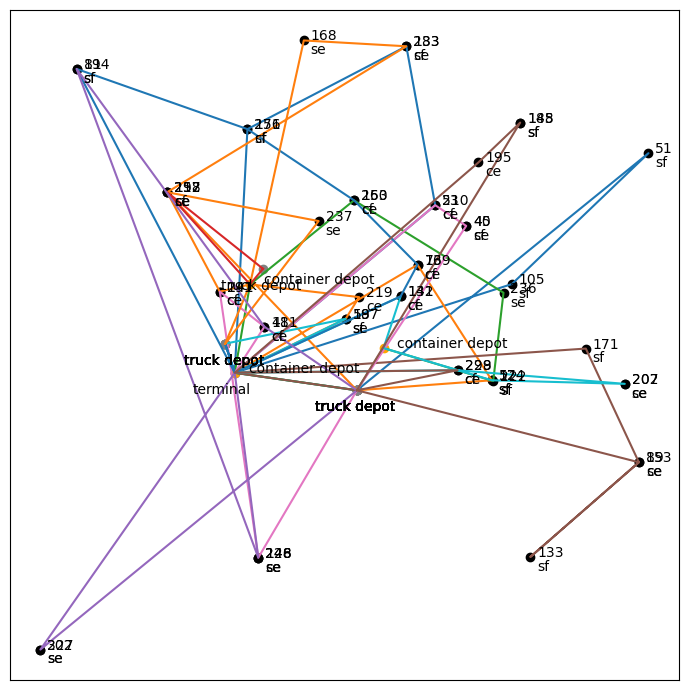

In [17]:
# plot the result
fig, ax = plt.subplots(figsize=(7, 7))

# scatter plot of requests, time windows and depots
for request in list_request:
    ax.scatter(request.x, request.y, color='black')
    ax.annotate(f'{request.type}', (request.x, request.y), xytext=(5, -10), textcoords='offset points')
    # ax.annotate(f'[{request.e}, {request.l}]', (request.x, request.y), xytext=(-45, 5), textcoords='offset points')
for terminal in list_terminal:
    ax.scatter(terminal.x, terminal.y, color='blue')
    ax.annotate(f'terminal', (terminal.x, terminal.y), xytext=(-30, -15), textcoords='offset points')
for container_depot in list_container_depot:
    ax.scatter(container_depot.x, container_depot.y, color='orange')
    ax.annotate(f'container depot', (container_depot.x, container_depot.y), xytext=(10, 0), textcoords='offset points')
for fleet in list_fleet:
    ax.scatter(fleet.x, fleet.y, color='gray')
    ax.annotate(f'truck depot', (fleet.x, fleet.y), xytext=(-30, -15), textcoords='offset points')

# plot the path
for fleet in list_fleet:
    x, y = [], []
    for node in result_path[fleet.id]:
        if node[1][:3] == 'tmd':
            x.append(list_terminal[int(list_request[int(node[1][-3:])].terminal_index)].x)
            y.append(list_terminal[int(list_request[int(node[1][-3:])].terminal_index)].y)
        elif node[1][:3] in {'cfd', 'ced', 'sfd', 'sed'}:
            x.append(list_request[int(node[1][-3:])].x)
            y.append(list_request[int(node[1][-3:])].y)
            ax.annotate(node[0], (list_request[int(node[1][-3:])].x, list_request[int(node[1][-3:])].y), xytext=(5, 0), textcoords='offset points')
        elif node[1][:3] in {'cdd', 'cdp'}:
            x.append(list_container_depot[int(node[1][-3:])].x)
            y.append(list_container_depot[int(node[1][-3:])].y)
        elif node[1][:2] in {'ts', 'te'}:
            x.append(list_fleet[int(node[1][-3:])].x)
            y.append(list_fleet[int(node[1][-3:])].y)
    
    ax.plot(x, y, color=f'C{int(fleet.id)}')

# 축 값 제거
ax.set_xticks([])
ax.set_yticks([])

plt.tight_layout()

# ax.legend(bbox_to_anchor=(0., 1.01, 1., 0.1), loc='lower left', ncols=3, mode='expand', borderaxespad=0)
plt.show()

# 그림 저장
fig.savefig(f'{dir_forder_save}\\route-{save_name}.png')

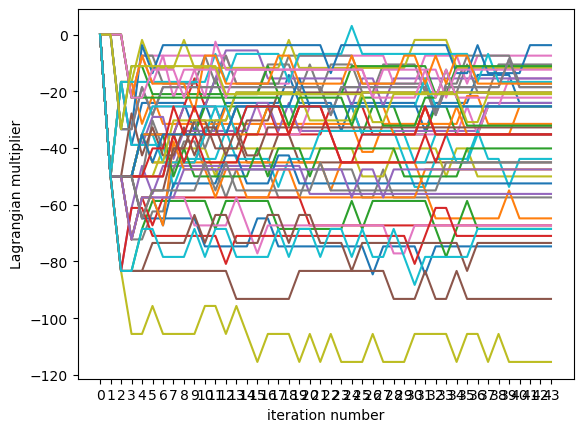

In [18]:
# LM graph
fig, ax = plt.subplots()
for _, lm in result_lm.items():
    ax.plot(lm)
    
ax.set_xlabel('iteration number')
ax.set_ylabel('Lagrangian multiplier')
ax.set_xticks(range(k+1))

# LM 그래프 저장
fig.savefig(f'{dir_forder_save}\\LM-{save_name}.png')